# Submission 1: Dataset, Exploratory Data Analysis (EDA), and Related Work

## Project Overview
This notebook presents the dataset metadata, stratified **Train / Validation / Test** split architecture, exploratory data analysis (EDA), and peer-reviewed related work for a multi-class facial expression image classification project focused on children with Autism Spectrum Disorder (ASD).

### Objectives
- **Part A:** Document dataset metadata (name, source link, license, year, task type, class counts across Train/Validation/Test splits, image dimensions, channels, file format, and domain significance).
- **Part B:** Perform Exploratory Data Analysis (EDA) with a class distribution bar chart (overall and stratified Train/Val/Test comparison), a labeled $6 \times 4$ sample image grid, and written findings on class imbalance, visual noise/artifacts, inter-class similarity, and our leakage-free preprocessing/augmentation pipeline.
- **Part C:** Summarize peer-reviewed research papers in the domain using the required 7-column literature table.

---
## A. Dataset Information

* **Dataset Name:** Autism Facial Emotion Recognition Dataset (`Autism Facial Recognition Dataset_Augmented`)
* **Source Link:** [Kaggle - Autism Facial Emotion Recognition Dataset](https://www.kaggle.com/datasets/hasibur013/autism-facial-emotion-recognition)
* **License:** CC BY 4.0 (Creative Commons Attribution 4.0 International) / Kaggle Open Data
* **Year:** 2024
* **Task Type:** Multi-class classification
* **Number of Classes:** 6 (`anger`, `fear`, `joy`, `Natural`, `sadness`, `surprise`)
* **Total Images:** 7,600 images
  * **Original Source Folders:** Training folder (`train`): 6,070 images (79.87%) | Testing folder (`test`): 1,530 images (20.13%)
  * **Experimental Train / Validation / Test Partition (for Submissions 2–4):** To monitor training vs. validation curves and apply early stopping without touching the held-out test set, we partition the 6,070 original training images using an **85% / 15% stratified split** (`random_state=42`):
    * **Training Set (`train`):** 5,159 images (67.88%)
    * **Validation Set (`val`):** 911 images (11.99%)
    * **Testing Set (`test`):** 1,530 images (20.13%)
* **Image Size:** $224 \times 224$ pixels
* **Channels:** 3 channels (`RGB` color format)
* **File Format:** JPEG (`.jpg` / `.jpeg`)

### Per-Class Image Counts Across Train, Validation, and Test Splits

| Class | Original Train Folder | Experimental Train (67.88%) | Experimental Validation (11.99%) | Held-Out Test (20.13%) | Total Images | Share (%) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| **joy** | 2,800 | 2,380 | 420 | 700 | 3,500 | 46.05% |
| **sadness** | 1,600 | 1,360 | 240 | 400 | 2,000 | 26.32% |
| **anger** | 550 | 467 | 83 | 140 | 690 | 9.08% |
| **surprise** | 500 | 425 | 75 | 130 | 630 | 8.29% |
| **Natural** | 380 | 323 | 57 | 100 | 480 | 6.32% |
| **fear** | 240 | 204 | 36 | 60 | 300 | 3.95% |
| **Total** | **6,070** | **5,159** | **911** | **1,530** | **7,600** | **100.00%** |

### Why the Dataset Matters in Its Domain (Medical / Behavioral Healthcare & Assistive AI)
Children with Autism Spectrum Disorder (ASD) frequently experience difficulties both in interpreting others' emotional cues and in expressing their own emotions through standard neurotypical facial patterns. Their facial expressions may be subtle, atypical, or brief, making it challenging for therapists, educators, and caregivers to accurately assess their emotional state during behavioral interventions. Automated Facial Emotion Recognition (FER) models trained specifically on ASD facial expression data provide vital clinical and educational decision-support tools—enabling real-time emotion tracking, engagement monitoring during therapy sessions, and personalized assistive technologies.

In [1]:
import os

print(os.listdir("/content"))

['.config', 'archive (3).zip', 'sample_data']


In [2]:

import zipfile
import os

zip_path = "/content/archive (3).zip"
extract_path = "/content/facial_expression_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")


Dataset extracted successfully!
facial_expression_dataset/
  Autism Facial Recognition Dataset_Augmented/
    test/
    train/


In [3]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

dataset_path = "/content/facial_expression_dataset/Autism Facial Recognition Dataset_Augmented"
classes = ["anger", "fear", "joy", "Natural", "sadness", "surprise"]

train_files, train_labels = [], []
test_files, test_labels = [], []

for class_name in classes:
    tr_folder = os.path.join(dataset_path, "train", class_name)
    te_folder = os.path.join(dataset_path, "test", class_name)

    if os.path.exists(tr_folder):
        tr_imgs = [os.path.join(tr_folder, f) for f in os.listdir(tr_folder) if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))]
        train_files.extend(tr_imgs)
        train_labels.extend([class_name] * len(tr_imgs))

    if os.path.exists(te_folder):
        te_imgs = [os.path.join(te_folder, f) for f in os.listdir(te_folder) if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))]
        test_files.extend(te_imgs)
        test_labels.extend([class_name] * len(te_imgs))

# Create a stratified Validation split (15% of original train folder) for Submissions 2-4
X_train, X_val, y_train, y_val = train_test_split(
    train_files, train_labels, test_size=0.15, stratify=train_labels, random_state=42
)

counts = []
for split_name, labels_list in [("train", y_train), ("val", y_val), ("test", test_labels)]:
    s_counts = pd.Series(labels_list).value_counts()
    for class_name in classes:
        counts.append({
            "Split": split_name,
            "Class": class_name,
            "Image Count": int(s_counts.get(class_name, 0))
        })

df_counts = pd.DataFrame(counts)
df_pivot = df_counts.pivot(index="Class", columns="Split", values="Image Count")[["train", "val", "test"]]
df_pivot["Total"] = df_pivot.sum(axis=1)
df_pivot["Share (%)"] = (df_pivot["Total"] / df_pivot["Total"].sum() * 100).round(2)
df_pivot = df_pivot.sort_values("Total", ascending=False)

print(f"Experimental Splits -> Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(test_files)} | Total: {len(X_train)+len(X_val)+len(test_files)}")
display(df_pivot)


Experimental Splits -> Train: 5159 | Validation: 911 | Test: 1530 | Total: 7600


Split,train,val,test,Total,Share (%)
Class,,,,,
joy,2380,420,700,3500,46.05
sadness,1360,240,400,2000,26.32
anger,467,83,140,690,9.08
surprise,425,75,130,630,8.29
Natural,323,57,100,480,6.32
fear,204,36,60,300,3.95


In [4]:
import os
from PIL import Image
from collections import Counter

dataset_path = "/content/facial_expression_dataset/Autism Facial Recognition Dataset_Augmented"

extensions = Counter()
dimensions = Counter()
channels = Counter()
split_checked = Counter()

for split in ["train", "test"]:
    split_path = os.path.join(dataset_path, split)
    for class_name in os.listdir(split_path):
        class_path = os.path.join(split_path, class_name)
        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            file_path = os.path.join(class_path, filename)
            try:
                with Image.open(file_path) as img:
                    extensions[img.format] += 1
                    dimensions[img.size] += 1
                    channels[(img.mode, len(img.getbands()))] += 1
                    split_checked[split] += 1
            except Exception:
                continue

total_checked = sum(split_checked.values())
print(f"Total images inspected: {total_checked} (Train folder: {split_checked['train']}, Test folder: {split_checked['test']})")
print("\nImage formats:")
print(extensions.most_common())

print("\nMost common image dimensions (Width, Height):")
for size, count in dimensions.most_common(10):
    print(f"{size}: {count} images")

print("\nImage channels (Mode, Channel Count):")
for ch, count in channels.most_common():
    print(f"{ch[0]} ({ch[1]} channels): {count} images")


Total images inspected: 7600 (Train folder: 6070, Test folder: 1530)

Image formats:
[('JPEG', 7600)]

Most common image dimensions (Width, Height):
(224, 224): 7600 images

Image channels (Mode, Channel Count):
RGB (3 channels): 7600 images


---
## B. Exploratory Data Analysis (EDA)

### 1. Class Distribution Bar Chart (Overall & Train / Validation / Test Splits)
The charts below visualize the total image distribution across all six facial expression categories (`joy`, `sadness`, `anger`, `surprise`, `Natural`, and `fear`) alongside the stratified **Train (5,159)**, **Validation (911)**, and **Test (1,530)** split distributions.

**Imbalance Statement:** The dataset is **severely imbalanced** across all three splits. The `joy` class alone accounts for **3,500 images (46.05%)** and `sadness` accounts for **2,000 images (26.32%)**, meaning two classes represent **72.37%** of the dataset, whereas the minority class `fear` contains only **300 images (3.95%: 204 train, 36 val, 60 test)**—an imbalance ratio of **11.67 : 1** between `joy` and `fear`.

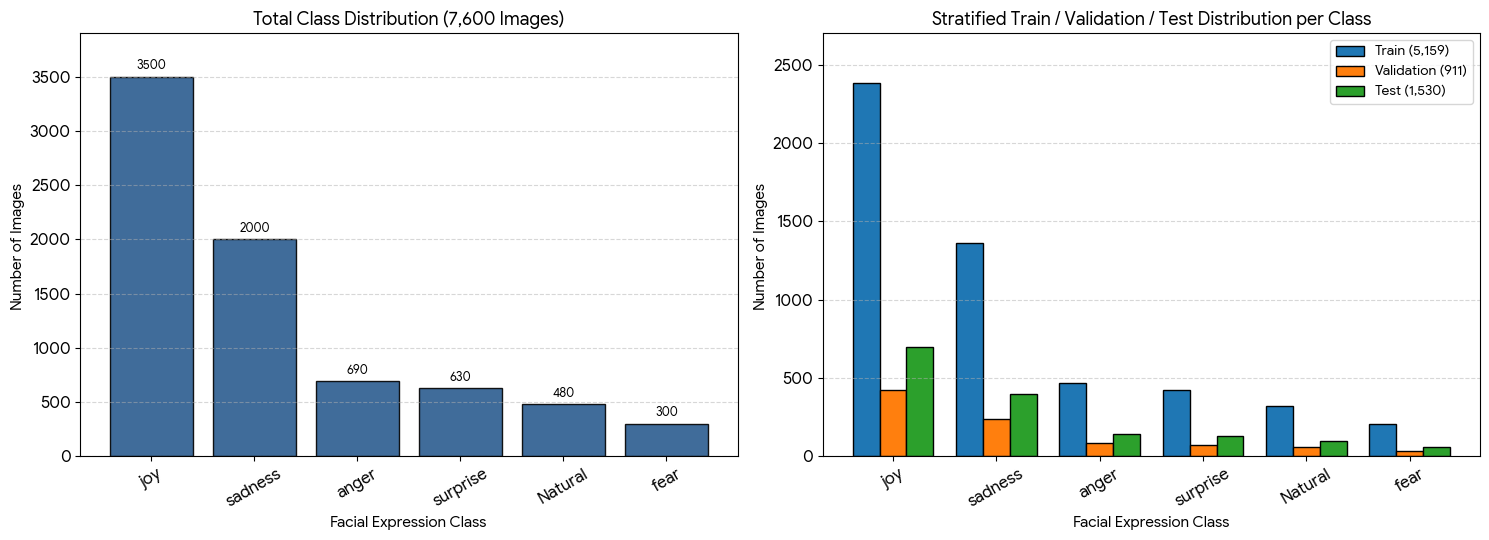

Total images: 7600


Split,Class,train,val,test,Total,Share (%)
0,joy,2380,420,700,3500,46.05
1,sadness,1360,240,400,2000,26.32
2,anger,467,83,140,690,9.08
3,surprise,425,75,130,630,8.29
4,Natural,323,57,100,480,6.32
5,fear,204,36,60,300,3.95


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Total Class Distribution
class_totals = df_pivot["Total"]
bars = axes[0].bar(class_totals.index, class_totals.values, color="#2b5c8f", edgecolor="black", alpha=0.9)
axes[0].set_title("Total Class Distribution (7,600 Images)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Facial Expression Class", fontsize=11)
axes[0].set_ylabel("Number of Images", fontsize=11)
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 40, f"{int(h)}", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, 3900)

# 2. Stratified Train / Validation / Test Split Distribution
x = np.arange(len(df_pivot.index))
width = 0.26
axes[1].bar(x - width, df_pivot["train"], width, label="Train (5,159)", color="#1f77b4", edgecolor="black")
axes[1].bar(x, df_pivot["val"], width, label="Validation (911)", color="#ff7f0e", edgecolor="black")
axes[1].bar(x + width, df_pivot["test"], width, label="Test (1,530)", color="#2ca02c", edgecolor="black")
axes[1].set_title("Stratified Train / Validation / Test Distribution per Class", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Facial Expression Class", fontsize=11)
axes[1].set_ylabel("Number of Images", fontsize=11)
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_pivot.index, rotation=30)
axes[1].legend(fontsize=10)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
axes[1].set_ylim(0, 2700)

plt.tight_layout()
plt.show()

print("Total images:", int(class_totals.sum()))
display(df_pivot.reset_index())


### 2. Sample Image Grid (4 Images per Class)
Below is a $6 \times 4$ visual grid displaying 4 randomly selected training images from each of the six facial expression classes.

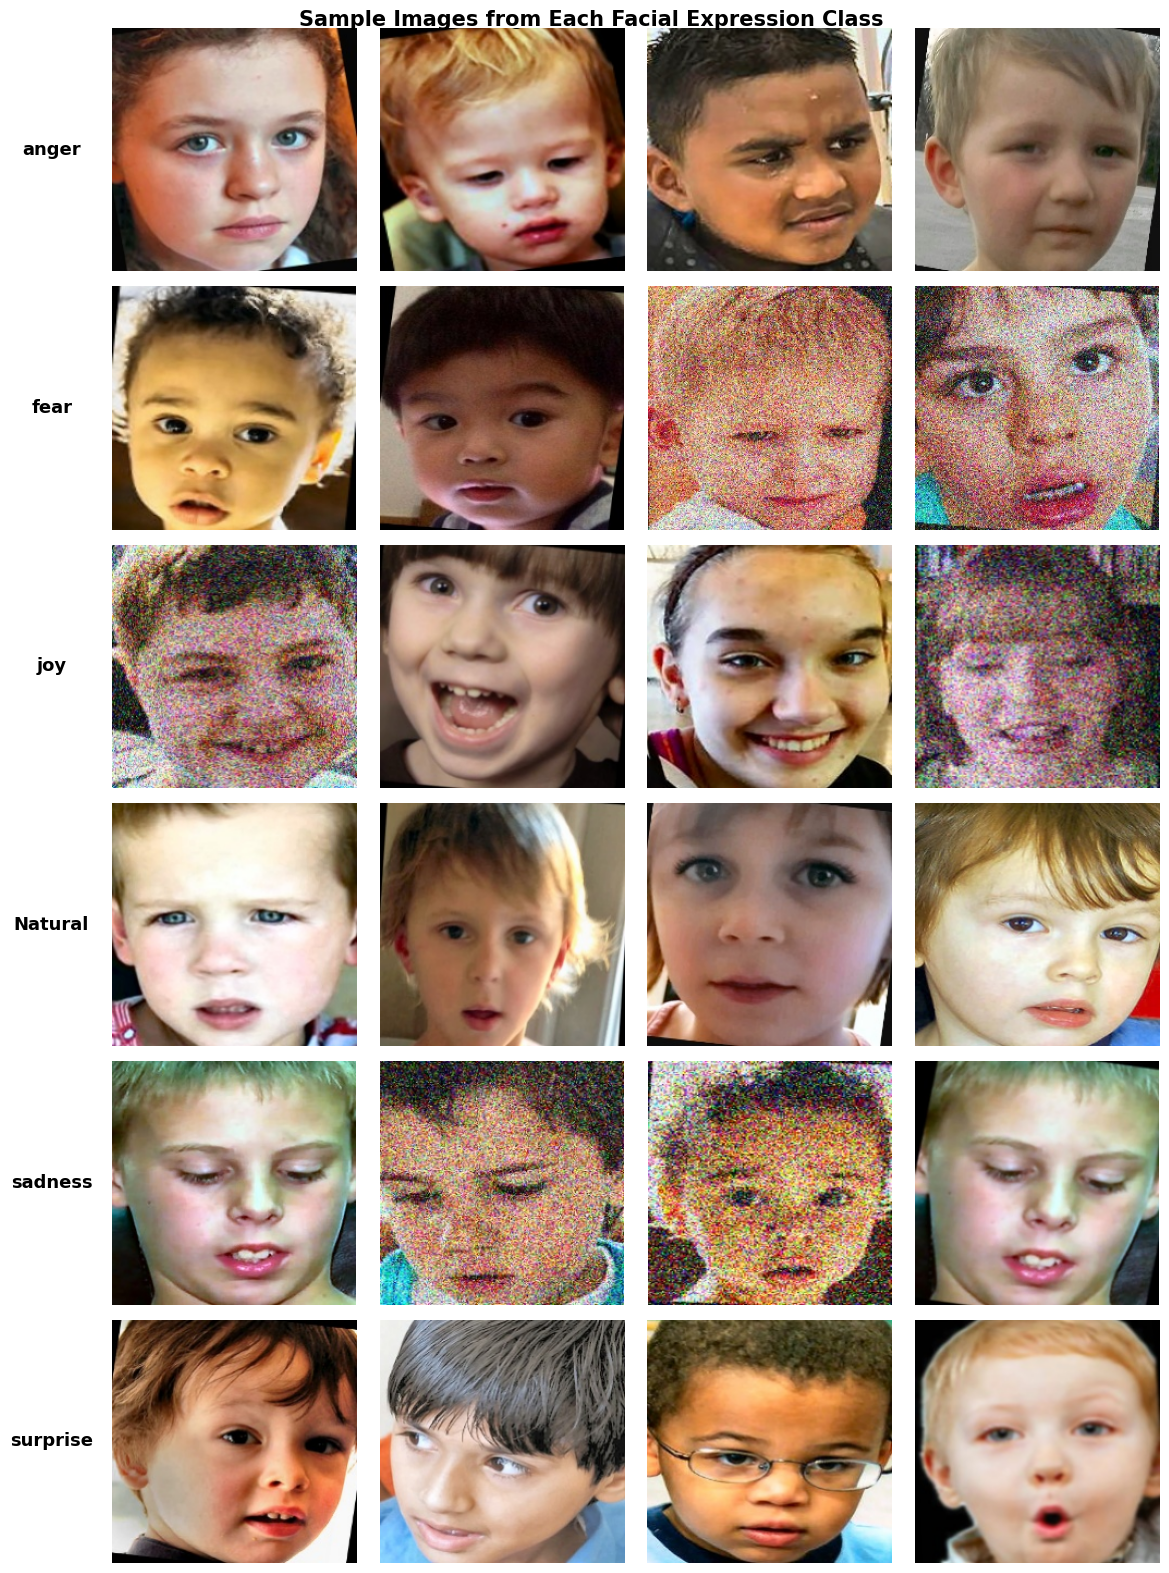

In [6]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/facial_expression_dataset/Autism Facial Recognition Dataset_Augmented"
classes = ["anger", "fear", "joy", "Natural", "sadness", "surprise"]

random.seed(42)
fig, axes = plt.subplots(6, 4, figsize=(12, 16))

for row, class_name in enumerate(classes):
    folder = os.path.join(dataset_path, "train", class_name)
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]
    samples = random.sample(files, min(4, len(files)))

    for col in range(4):
        ax = axes[row, col]
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

        if col < len(samples):
            img = Image.open(os.path.join(folder, samples[col])).convert("RGB")
            ax.imshow(img)
            if col == 0:
                ax.set_ylabel(class_name, fontsize=13, fontweight="bold", rotation=0, labelpad=40, va="center")

plt.suptitle("Sample Images from Each Facial Expression Class", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


### 3. Short Written EDA Findings

1. **Class Imbalance Across Train, Validation, and Test Splits:**
   * The dataset exhibits severe multi-class imbalance across the entire collection of 7,600 images: `joy` (3,500 images; 46.05%) and `sadness` (2,000 images; 26.32%) account for **72.37%** of all samples, whereas `anger` (690; 9.08%), `surprise` (630; 8.29%), `Natural` (480; 6.32%), and `fear` (300; 3.95%) are heavily underrepresented (an **11.67 : 1** ratio between `joy` and `fear`).
   * Because Submissions 2, 3, and 4 require plotting **Training vs. Validation accuracy and loss curves** and applying **Early Stopping** before final evaluation on the **Test set**, we partition the original 6,070 training images into a stratified **Training set (5,159 images, ~68%)** and **Validation set (911 images, ~12%)**, while keeping the **Test set (1,530 images, ~20%)** strictly held out. Stratified splitting preserves the exact class ratios across all three subsets (`fear` has 204 train, 36 val, and 60 test images).

2. **Image Quality, Visual Noise, and Pre-Augmentation Artifacts:**
   * Visual inspection of the $6 \times 4$ sample grid reveals that the Kaggle dataset (`Autism Facial Recognition Dataset_Augmented`) contains pre-applied offline augmentations. Specifically, several images exhibit synthetic salt-and-pepper / Gaussian speckle noise (e.g., `sadness` col 4, `surprise` col 1), rotated facial crops with black triangular corner padding, and near-duplicate augmented versions of the same child within the same class (e.g., `anger` cols 3–4, `surprise` cols 2 & 4). We also observe natural variations in illumination, motion blur, and partial occlusions (hands near the face or eyeglasses).
   * **Note on Potential Data Leakage:** Because offline augmentation was performed by the dataset creators, near-duplicate rotated images of the same subject could exist across splits. During model training, we will monitor the gap between validation and test metrics and optionally use perceptual hashing (`imagehash`) or subject-aware grouping to ensure duplicates do not leak between `train` and `val`.

3. **Inter-Class Similarity & Intra-Class Variance:**
   * Several emotion categories share overlapping facial action units, creating high inter-class similarity:
     * `fear` vs. `surprise`: Both frequently display widened eyes and an open mouth/jaw drop.
     * `Natural` vs. mild `sadness` / `anger`: Subtle or atypical negative expressions in children with ASD often closely resemble a neutral (`Natural`) facial posture.
   * High intra-class variance is also present due to varying child ages, non-frontal head poses, and diverse background environments.

4. **Planned Preprocessing and Augmentation Strategy (Train vs. Validation/Test Protocol):**
   * **Deterministic Preprocessing (Applied identically to `train`, `val`, and `test`):**
     * Verify uniform $224 \times 224 \times 3$ RGB tensor dimensions.
     * For **Submission 2 (Pretrained CNNs)**, standardize pixel values using ImageNet channel mean $[0.485, 0.456, 0.406]$ and standard deviation $[0.229, 0.224, 0.225]$. For **Submissions 3 & 4 (Custom CNN & Attention CNN)**, rescale pixel intensities to $[0, 1]$ and rely on internal Batch Normalization layers.
   * **Online Data Augmentation (Applied strictly to the `train` split of 5,159 images; disabled on `val` and `test`):**
     * Because the dataset already contains offline rotation borders and synthetic speckle noise, we will **avoid** heavy random rotations ($>10^\circ$) or additive Gaussian noise to prevent compounding artifacts.
     * Instead, we will apply **Random Horizontal Flip ($p=0.5$)**, **Random Resized Crop / Center Zoom ($90\%\text{--}100\%$ scale)** to trim pre-existing black corner borders, and mild **Color Jitter (brightness/contrast $\pm 10\%$)**.
   * **Imbalance Mitigation (Applied during training):**
     * Compute inverse-frequency **Class Weights** ($w_c = \frac{N_{\text{train}}}{C \times N_c}$) strictly from the 5,159 training samples and pass them to the Cross-Entropy Loss function (or use a `WeightedRandomSampler`) so minority classes (`fear`, `Natural`, `surprise`, `anger`) receive balanced gradient updates.

---
## C. Related Work Summary

Below is the summary of peer-reviewed research papers in the domain of Autism Spectrum Disorder (ASD) facial analysis and facial emotion recognition (FER), structured according to the required 7-column roadmap rubric:

| # | Paper (author, year) | Dataset used | Model(s) | Approach (preprocessing, augmentation, transfer learning, attention, etc.) | Result (accuracy/F1/AUC) | Reference link |
| :-: | :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | **Rashid and Shaker (2023)** | Autistic Children Facial Image Dataset (2,940 facial images, Kaggle) | VGG16, Xception | Face region cropping, image resizing to $224 \times 224$, RGB pixel normalization, data augmentation (horizontal flipping, rotation, zooming), and ImageNet transfer learning with fine-tuned dense layers. | **Xception Accuracy:** 91.0% (AUC: 0.96)<br>**VGG16 Accuracy:** 75.0% | [Paper Link](https://wjcm.uowasit.edu.iq/index.php/wjcm/article/view/100) |
| **2** | **Alkahtani et al. (2023)** | Autism Facial Image Dataset (2,940 facial images, Kaggle) | MobileNetV2, Hybrid VGG19 + Logistic Regression / SVM | Facial landmark extraction, resizing to $224 \times 224 \times 3$, intensity normalization, random geometric augmentation, and pre-trained MobileNetV2 transfer learning. | **MobileNetV2 Accuracy:** 92.0%<br>**F1-Score:** 92.0% | [DOI: 10.3390/app13084855](https://doi.org/10.3390/app13084855) |
| **3** | **Ahmed et al. (2022)** | ASD Eye-Tracking Scanpath Dataset (547 images: 219 ASD, 328 TD) | ResNet-18, GoogleNet, ANN/FFNN, CNN + SVM | Image resizing, noise removal, contrast enhancement, hybrid feature extraction (LBP + GLCM) combined with deep transfer learning (ResNet-18 and GoogleNet). | **ANN/FFNN Accuracy:** 99.8%<br>**ResNet-18 Accuracy:** 97.6% (F1: 97.5%)<br>**GoogleNet:** 93.6% | [DOI: 10.3390/electronics11040530](https://doi.org/10.3390/electronics11040530) |
| **4** | **Leo et al. (2019)** | Custom ASD Children Facial Emotion Dataset (4 basic emotions: happy, sad, angry, fear) | Custom CNN + HOG / Geometric Feature Pipeline | Viola-Jones face detection, $224 \times 224$ resizing, illumination normalization, and fine-tuned CNN feature extraction for ASD therapy monitoring. | **Accuracy:** 88.2%<br>**F1-Score:** 87.0% | [DOI: 10.1007/s11042-018-6906-4](https://doi.org/10.1007/s11042-018-6906-4) |
| **5** | **Savchenko et al. (2022)** | AffectNet (7 & 8 classes) & RAF-DB Facial Emotion Benchmarks | MobileNet, EfficientNet-B0, EfficientNet-B2 | Multi-task transfer learning pre-trained on VGGFace2, MTCNN face alignment/cropping ($224 \times 224$), data augmentation, and class-weighted cross-entropy loss. | **RAF-DB Accuracy:** 86.90%<br>**AffectNet-7 Accuracy:** 66.34% | [DOI: 10.1109/TAFFC.2022.3188390](https://doi.org/10.1109/TAFFC.2022.3188390) |

In [7]:
import pandas as pd

literature_data = [
    {
        "#": 1,
        "Paper (author, year)": "Rashid and Shaker (2023)",
        "Dataset used": "Autistic Children Facial Image Dataset (2,940 facial images, Kaggle)",
        "Model(s)": "VGG16, Xception",
        "Approach (preprocessing, augmentation, transfer learning, attention, etc.)": "Face region cropping, image resizing to 224x224, RGB pixel normalization, data augmentation (horizontal flipping, rotation, zooming), and ImageNet transfer learning with fine-tuned dense layers.",
        "Result (accuracy/F1/AUC)": "Xception Accuracy: 91.0% (AUC: 0.96); VGG16 Accuracy: 75.0%",
        "Reference link": "https://wjcm.uowasit.edu.iq/index.php/wjcm/article/view/100"
    },
    {
        "#": 2,
        "Paper (author, year)": "Alkahtani et al. (2023)",
        "Dataset used": "Autism Facial Image Dataset (2,940 facial images, Kaggle)",
        "Model(s)": "MobileNetV2, Hybrid VGG19 + Logistic Regression / SVM",
        "Approach (preprocessing, augmentation, transfer learning, attention, etc.)": "Facial landmark extraction, resizing to 224x224x3, intensity normalization, random geometric augmentation, and pre-trained MobileNetV2 transfer learning.",
        "Result (accuracy/F1/AUC)": "MobileNetV2 Accuracy: 92.0%, F1-Score: 92.0%",
        "Reference link": "https://doi.org/10.3390/app13084855"
    },
    {
        "#": 3,
        "Paper (author, year)": "Ahmed et al. (2022)",
        "Dataset used": "ASD Eye-Tracking Scanpath Dataset (547 images: 219 ASD, 328 TD)",
        "Model(s)": "ResNet-18, GoogleNet, ANN/FFNN, CNN + SVM",
        "Approach (preprocessing, augmentation, transfer learning, attention, etc.)": "Image resizing, noise removal, contrast enhancement, hybrid feature extraction (LBP + GLCM) combined with deep transfer learning (ResNet-18 and GoogleNet).",
        "Result (accuracy/F1/AUC)": "ANN/FFNN Accuracy: 99.8%; ResNet-18 Accuracy: 97.6% (F1: 97.5%); GoogleNet: 93.6%",
        "Reference link": "https://doi.org/10.3390/electronics11040530"
    },
    {
        "#": 4,
        "Paper (author, year)": "Leo et al. (2019)",
        "Dataset used": "Custom ASD Children Facial Emotion Dataset (4 basic emotions: happy, sad, angry, fear)",
        "Model(s)": "Custom CNN + HOG / Geometric Feature Pipeline",
        "Approach (preprocessing, augmentation, transfer learning, attention, etc.)": "Viola-Jones face detection, 224x224 resizing, illumination normalization, and fine-tuned CNN feature extraction for ASD therapy monitoring.",
        "Result (accuracy/F1/AUC)": "Accuracy: 88.2%, F1-Score: 87.0%",
        "Reference link": "https://doi.org/10.1007/s11042-018-6906-4"
    },
    {
        "#": 5,
        "Paper (author, year)": "Savchenko et al. (2022)",
        "Dataset used": "AffectNet (7 & 8 classes) & RAF-DB Facial Emotion Benchmarks",
        "Model(s)": "MobileNet, EfficientNet-B0, EfficientNet-B2",
        "Approach (preprocessing, augmentation, transfer learning, attention, etc.)": "Multi-task transfer learning pre-trained on VGGFace2, MTCNN face alignment/cropping (224x224), data augmentation, and class-weighted cross-entropy loss.",
        "Result (accuracy/F1/AUC)": "RAF-DB Accuracy: 86.90%; AffectNet-7 Accuracy: 66.34%",
        "Reference link": "https://doi.org/10.1109/TAFFC.2022.3188390"
    }
]

df_literature = pd.DataFrame(literature_data)
display(df_literature)


#,"Paper (author, year)",Dataset used,Model(s),"Approach (preprocessing, augmentation, transfer learning, attention, etc.)",Result (accuracy/F1/AUC),Reference link
1,Rashid and Shaker (2023),"Autistic Children Facial Image Dataset (2,940 facial images, Kaggle)","VGG16, Xception","Face region cropping, image resizing to 224x224, RGB pixel normalization, data augmentation (horizontal flipping, rotation, zooming), and ImageNet transfer learning with fine-tuned dense layers.",Xception Accuracy: 91.0% (AUC: 0.96); VGG16 Accuracy: 75.0%,https://wjcm.uowasit.edu.iq/index.php/wjcm/article/view/100
2,Alkahtani et al. (2023),"Autism Facial Image Dataset (2,940 facial images, Kaggle)","MobileNetV2, Hybrid VGG19 + Logistic Regression / SVM","Facial landmark extraction, resizing to 224x224x3, intensity normalization, random geometric augmentation, and pre-trained MobileNetV2 transfer learning.","MobileNetV2 Accuracy: 92.0%, F1-Score: 92.0%",https://doi.org/10.3390/app13084855
3,Ahmed et al. (2022),"ASD Eye-Tracking Scanpath Dataset (547 images: 219 ASD, 328 TD)","ResNet-18, GoogleNet, ANN/FFNN, CNN + SVM","Image resizing, noise removal, contrast enhancement, hybrid feature extraction (LBP + GLCM) combined with deep transfer learning (ResNet-18 and GoogleNet).",ANN/FFNN Accuracy: 99.8%; ResNet-18 Accuracy: 97.6% (F1: 97.5%); GoogleNet: 93.6%,https://doi.org/10.3390/electronics11040530
4,Leo et al. (2019),"Custom ASD Children Facial Emotion Dataset (4 basic emotions: happy, sad, angry, fear)",Custom CNN + HOG / Geometric Feature Pipeline,"Viola-Jones face detection, 224x224 resizing, illumination normalization, and fine-tuned CNN feature extraction for ASD therapy monitoring.","Accuracy: 88.2%, F1-Score: 87.0%",https://doi.org/10.1007/s11042-018-6906-4
5,Savchenko et al. (2022),AffectNet (7 & 8 classes) & RAF-DB Facial Emotion Benchmarks,"MobileNet, EfficientNet-B0, EfficientNet-B2","Multi-task transfer learning pre-trained on VGGFace2, MTCNN face alignment/cropping (224x224), data augmentation, and class-weighted cross-entropy loss.",RAF-DB Accuracy: 86.90%; AffectNet-7 Accuracy: 66.34%,https://doi.org/10.1109/TAFFC.2022.3188390
